# Learned Calibration | Generalization and Decision Value

This investigation asks when discovered subgroup corrections generalize, and whether better confidence leads to better escalation decisions.

It extends the original reference with repeated task-separated evaluation, a nonlinear predictive control, learned residual auditing, fresh-block confirmation, sample-budget and feature-mixture experiments, a decision-benefit model, and synthetic known-probability controls. These are new exploratory experiments on the existing public-data archive, developed with AI assistance.

The notebook reads measured full-study outputs. It does not call a coding model, execute generated programs, or download source data. There are 1,055 underlying tasks; repeated predictions and comparisons do not create new independent observations.


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
from IPython.display import Image, display

PROJECT = next(path for path in [Path.cwd(), *Path.cwd().parents]
               if (path / "research" / "advanced_protocol.json").exists())
RESULTS = PROJECT / "advanced_results"
SIMULATIONS = PROJECT / "simulation_results"

import sys
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from research.data import digest

for directory in (RESULTS, SIMULATIONS):
    manifest = json.loads((directory / "manifest.json").read_text())
    for name, expected in manifest["files"].items():
        assert digest(directory / name) == expected, name
summary = json.loads((RESULTS / "summary.json").read_text())
simulation_record = json.loads((SIMULATIONS / "simulation.json").read_text())
protocol = json.loads((RESULTS / "protocol.json").read_text())
assert not summary["smoke"] and not simulation_record["smoke"]
assert digest(RESULTS / "protocol.json") == summary["protocol_sha256"]
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")
print("Full outer folds:", summary["folds"])
print("Underlying task clusters:", summary["task_clusters"])
print("Probability rows across models and repeats:", summary["prediction_rows"])
print("Task-level policy objective records:", summary["task_cost_rows"])
print("All numerical manifests verified.")


Full outer folds: 15
Underlying task clusters: 1055
Probability rows across models and repeats: 316500
Task-level policy objective records: 379800
All numerical manifests verified.


## 1. What the repeated design separates

Three seeds each create five outer folds. A task is held out once per repeat, and all ten related answers remain in the same role. Base fitting, shared calibration, rule discovery, confirmation, policy selection, and evaluation use separate task sets.

The naïve and fixed-group auditors pool the discovery and confirmation tasks. The confirmation-filtered auditor discovers on one set and queries disjoint blocks of the other. They have the same available task pool, but use its labels differently.


In [2]:
plans = json.loads((RESULTS / "splits.json").read_text())
display(pd.DataFrame([{"role": role, "tasks": len(ids), "answers": 10*len(ids)}
                      for role, ids in plans[0]["roles"].items()]))
for plan in plans:
    sets = [set(ids) for ids in plan["roles"].values()]
    assert all(not left.intersection(right) for i, left in enumerate(sets) for right in sets[i+1:])
for seed in protocol["seeds"]:
    held = [task for plan in plans if plan["seed"] == seed for task in plan["roles"]["test"]]
    assert len(held) == len(set(held)) == summary["task_clusters"]
print("Verified: disjoint roles and one held-out appearance per task per repeat.")


,role,tasks,answers
0,train,379,3790
1,score_calibration,126,1260
2,discovery,126,1260
3,confirmation,105,1050
4,validation,108,1080
5,test,211,2110


Verified: disjoint roles and one held-out appearance per task per repeat.


## 2. Flexible prediction versus probability correction

The base predictors are standardized L2 logistic regression and regularized histogram gradient boosting. Boosting uses fixed settings and disables internal row-level early stopping, which could otherwise mix sibling answers across a hidden validation split.

Each base predictor has five variants. Raw estimates correctness directly; Platt adjusts the shared score scale; fixed groups patch predefined slices; tree auditing learns feature rules; confirmation-filtered auditing checks proposed corrections on fresh task blocks. These are fixed candidate pipelines, not exhaustive hyperparameter searches or isolated causal tests of one component.


In [3]:
folds = pd.read_csv(RESULTS / "fold_metrics.csv")
repeats = pd.read_csv(RESULTS / "repeat_summary.csv")
display(folds.groupby("method")[["brier", "log_loss", "auc", "ece", "worst"]].mean().sort_values("brier"))
display(repeats.groupby("method")["brier"].agg(["mean", "min", "max"]))
print("Repeat ranges are split-sensitivity diagnostics, not confidence intervals.")


,brier,log_loss,auc,ece,worst
method,,,,,
logistic/raw,0.108675,0.330056,0.928759,0.028039,0.202346
logistic/confirmed_tree,0.110451,0.336504,0.928721,0.039781,0.206948
logistic/platt,0.110565,0.336791,0.928759,0.040126,0.215396
histogram_boosting/raw,0.111144,0.337367,0.925081,0.032530,0.203429
logistic/tree_mc,0.111261,0.337754,0.927503,0.040486,0.220081
histogram_boosting/platt,0.112768,0.342301,0.925081,0.042475,0.219437
histogram_boosting/confirmed_tree,0.112788,0.342266,0.925060,0.042430,0.219437
histogram_boosting/tree_mc,0.113253,0.345119,0.924028,0.038431,0.220561
histogram_boosting/fixed_mc,0.114134,0.354429,0.921359,0.032299,0.205429


,mean,min,max
method,,,
histogram_boosting/confirmed_tree,0.112788,0.110843,0.114388
histogram_boosting/fixed_mc,0.114134,0.112892,0.115324
histogram_boosting/platt,0.112768,0.110858,0.114315
histogram_boosting/raw,0.111144,0.110172,0.111905
histogram_boosting/tree_mc,0.113253,0.112786,0.113991
logistic/confirmed_tree,0.110451,0.107746,0.114468
logistic/fixed_mc,0.114299,0.113917,0.114842
logistic/platt,0.110565,0.107441,0.115088
logistic/raw,0.108675,0.107615,0.110356


Repeat ranges are split-sensitivity diagnostics, not confidence intervals.


Raw logistic has the lowest mean Brier in this configuration. A more flexible base model or a correction layer is therefore a hypothesis to test, rather than an assumed improvement.

Within-base contrasts compare each variant with that same base's Platt scores. Loss differences are averaged within tasks across ten candidates and three repeats, then task means are resampled. **These descriptive intervals condition on overlapping fitted models and exclude refitting/split uncertainty and shared-training dependence.** There is no independent-replication or simultaneous-coverage claim.


,method,baseline,brier_difference,low,high,task_clusters
1,histogram_boosting/confirmed_tree,histogram_boosting/platt,0.000020,-0.000028,0.000072,1055
3,histogram_boosting/fixed_mc,histogram_boosting/platt,0.001366,-0.000731,0.003575,1055
5,histogram_boosting/platt,histogram_boosting/platt,0.000000,0.000000,0.000000,1055
7,histogram_boosting/raw,histogram_boosting/platt,-0.001624,-0.002569,-0.000637,1055
9,histogram_boosting/tree_mc,histogram_boosting/platt,0.000485,-0.000860,0.001909,1055
11,logistic/confirmed_tree,logistic/platt,-0.000114,-0.000423,0.000188,1055
13,logistic/fixed_mc,logistic/platt,0.003734,0.001380,0.005983,1055
15,logistic/platt,logistic/platt,0.000000,0.000000,0.000000,1055
17,logistic/raw,logistic/platt,-0.001889,-0.002790,-0.001009,1055
19,logistic/tree_mc,logistic/platt,0.000696,-0.000442,0.001841,1055


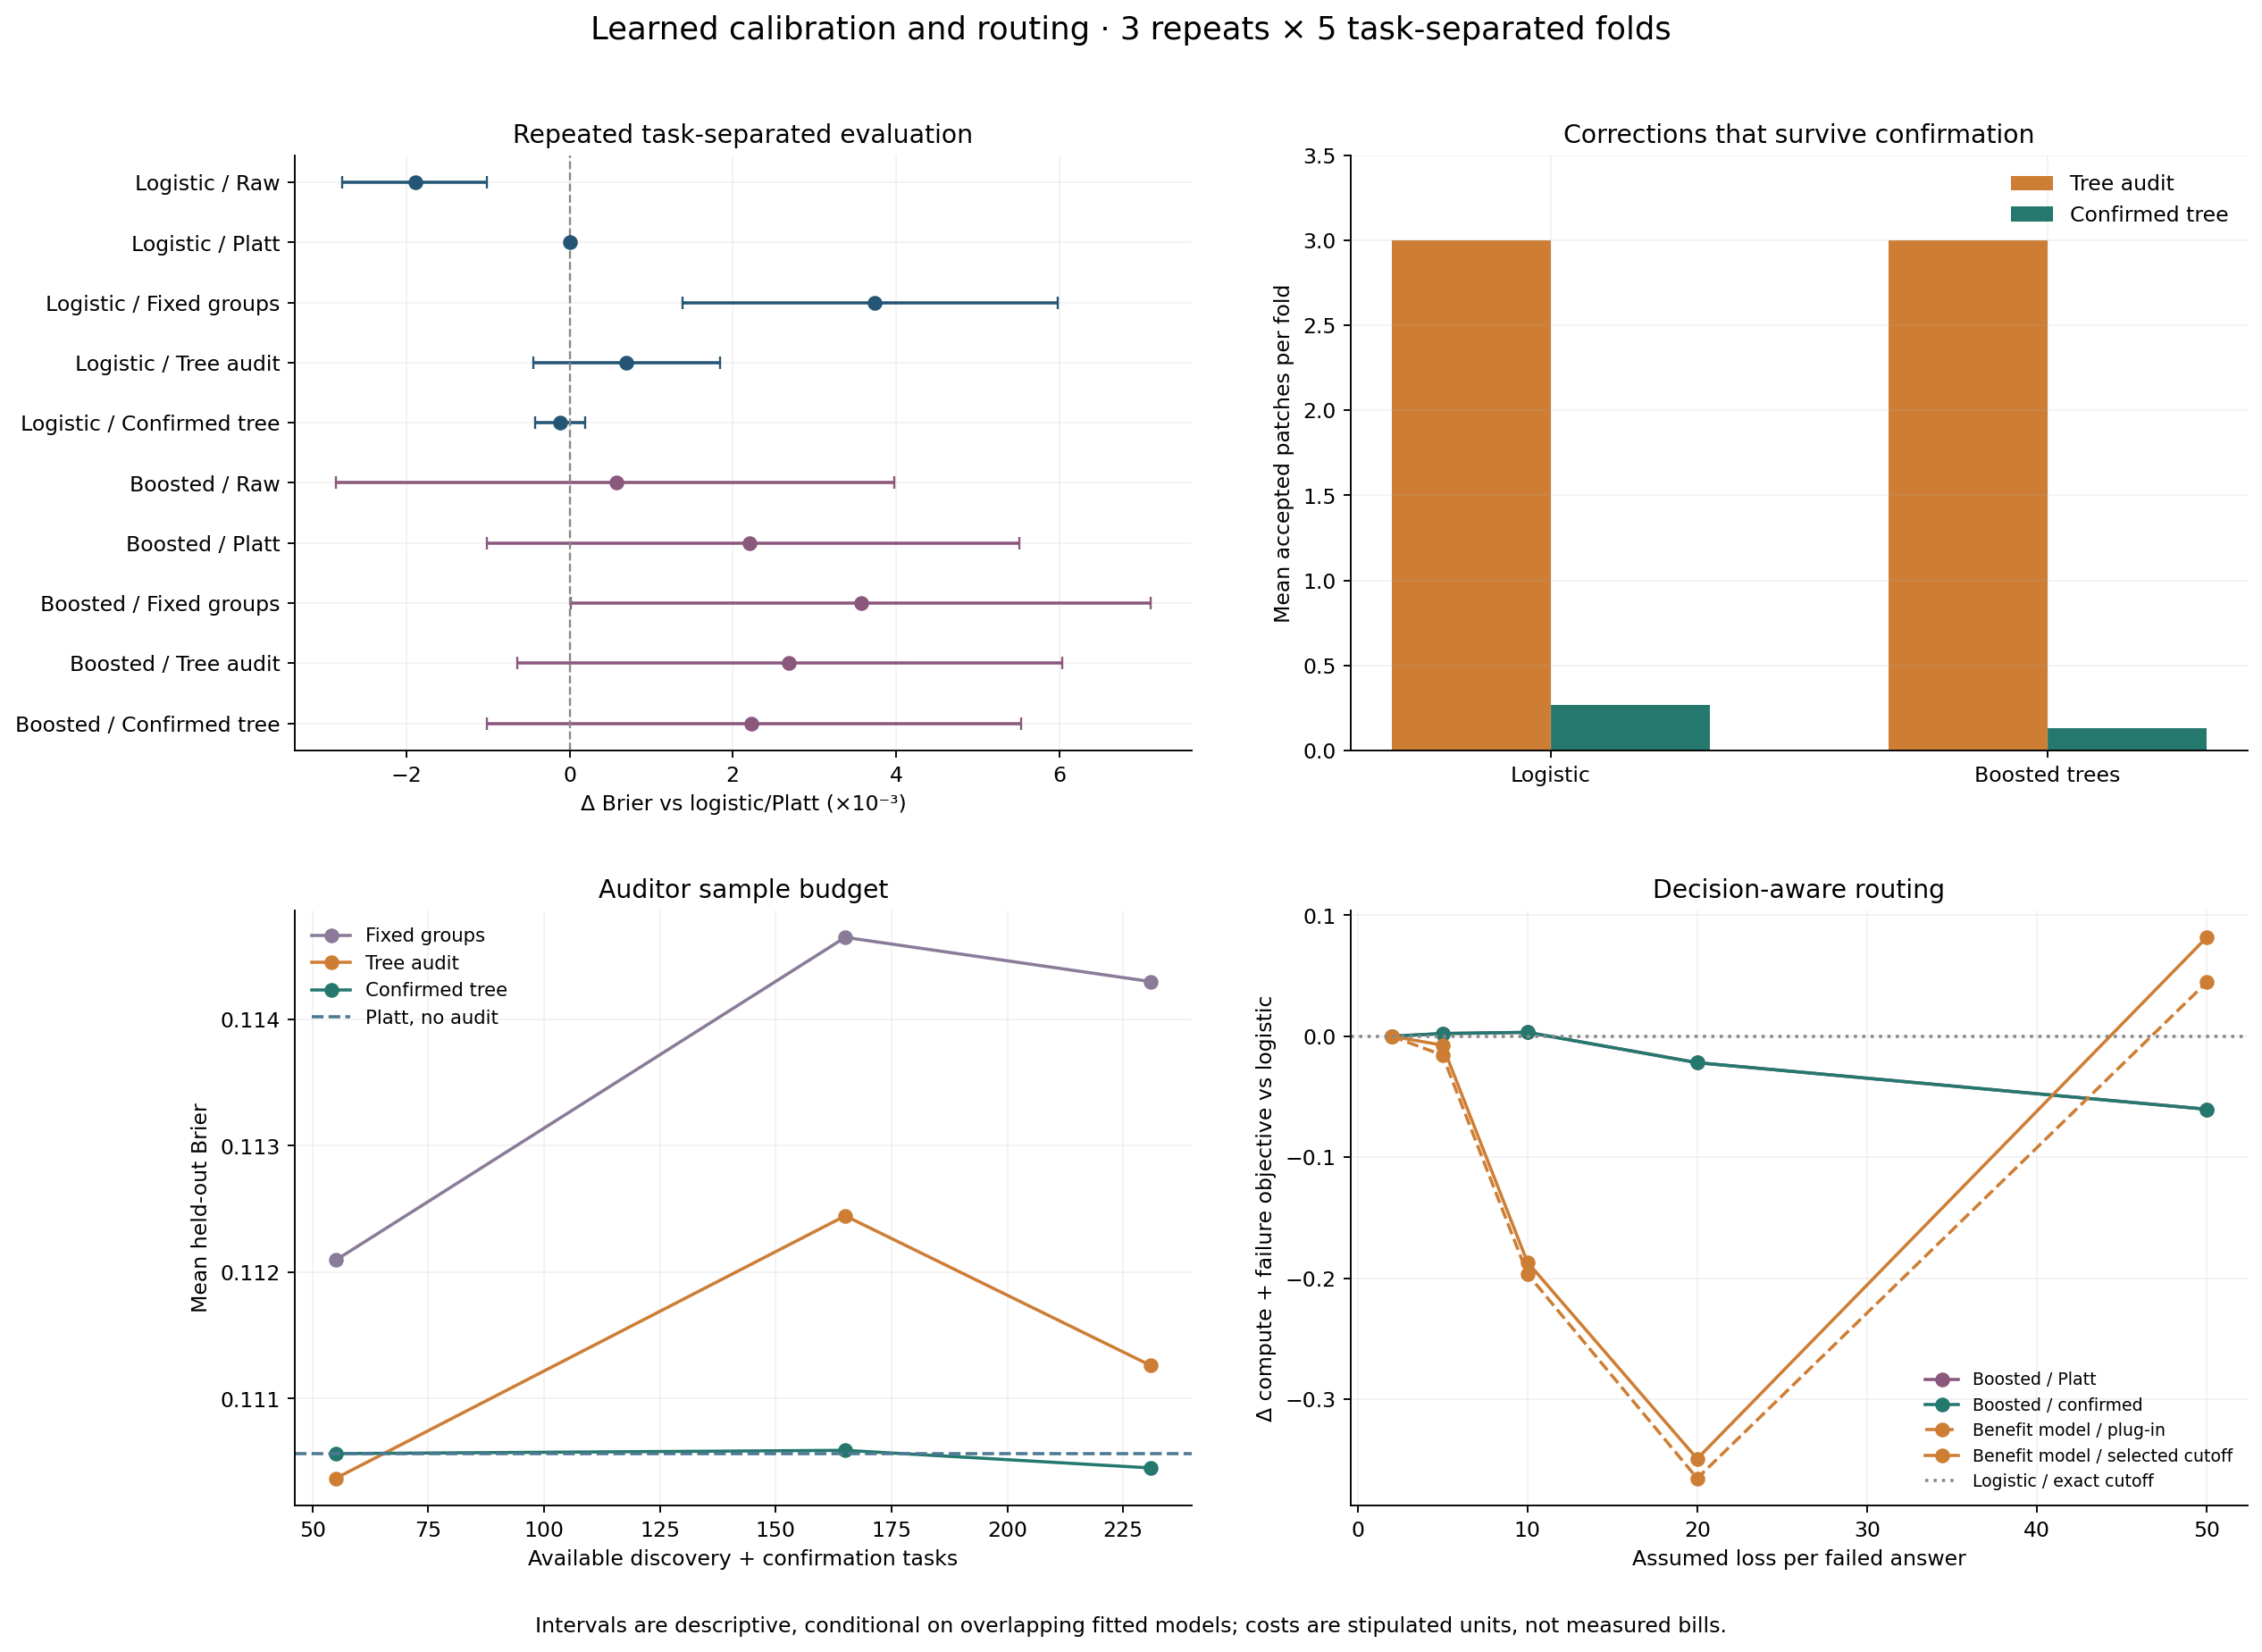

In [4]:
contrasts = pd.read_csv(RESULTS / "paired_comparisons.csv")
display(contrasts.query("contrast == 'within_base'")[["method", "baseline", "brier_difference", "low", "high", "task_clusters"]])
display(Image(filename=str(RESULTS / "advanced_diagnostics.png")))


## 3. How a subgroup is actually learned

Inside a current confidence band, a depth-two regression tree learns to predict residuals y minus p from the sixteen observable features. Each leaf defines a conjunction such as a token-score threshold combined with a code-size threshold. A root leaf can describe the whole score band.

The auditor scores supported regions by sample fraction times squared mean residual. This targets a potentially useful correction, but selecting the worst-looking region on noisy data also selects unusually extreme noise. Learned rules are approximate search results, not an exact auditor over every possible subgroup.

Below are the complete proposal traces from the first logistic fold, rather than a best-performing example chosen from the test results.


In [5]:
records = json.loads((RESULTS / "auditor_rules.json").read_text())
example = records[0]["models"]["logistic"]["calibrators"]

def describe_rule(rule):
    condition = " AND ".join(
        f"{item['feature']} {'<=' if item['side'] == 'le' else '>'} {item['threshold']:.5g}"
        for item in rule["conditions"]
    ) or "all feature values"
    return f"band {rule['bin']}: " + condition

for name in ("tree_mc", "confirmed_tree"):
    rows = []
    for proposal in example[name]["trace"]:
        interval = proposal.get("confirmation_interval", {})
        rows.append({"round": proposal["round"], "rule": describe_rule(proposal),
                     "discovery tasks": proposal["discovery_tasks"],
                     "discovery residual": proposal["discovery_residual"],
                     "confirmation tasks": proposal.get("confirmation_tasks"),
                     "confirmation low": interval.get("low"), "confirmation high": interval.get("high"),
                     "accepted": proposal["accepted"], "reason": proposal["reason"]})
    print(name)
    display(pd.DataFrame(rows))


tree_mc


,round,rule,discovery tasks,discovery residual,confirmation tasks,confirmation low,confirmation high,accepted,reason
0,0,band 2: log_code_chars <= 6.6572,25,-0.279097,None,None,None,True,patched
1,1,band 2: log_output_tokens > 6.6752 AND log_output_tokens <= 7.1217,43,0.198571,None,None,None,True,patched
2,2,band 3: log_code_chars > 6.7951 AND mean_logprob > -0.044686,23,0.233293,None,None,None,True,patched


confirmed_tree


,round,rule,discovery tasks,discovery residual,confirmation tasks,confirmation low,confirmation high,accepted,reason
0,0,band 2: functions > 0.5,26,0.169770,12,-0.437521,0.305599,False,unconfirmed_residual
1,1,band 2: functions > 0.5,26,0.169770,6,NaN,NaN,False,insufficient_confirmation_support
2,2,band 2: functions > 0.5,26,0.169770,13,-0.404493,0.270771,False,unconfirmed_residual


## 4. Independent confirmation and its price

The filter reserves three disjoint confirmation blocks. A rule is chosen before reading that block's outcomes. It requires at least eight represented tasks, a task-bootstrap residual interval excluding zero with the same sign as discovery, and applies n/(n+20) shrinkage.

Rejected proposals still consume their block. Ordered replay checks each rule against the current confidence band and never reads a new answer's outcome. The interval and alpha allocation are approximate; they establish no exact error-control or population multicalibration guarantee.

Accepted-patch counts measure behavior, not correctness on the real benchmark. Few accepted patches can reflect limited power as well as protection against overfitting.


In [6]:
counts = pd.DataFrame([
    {"base": base, "auditor": name, "patches": len(fit["patches"])}
    for record in records for base, details in record["models"].items()
    for name, fit in details["calibrators"].items()
])
display(counts.groupby(["base", "auditor"])["patches"].agg(["mean", "sum"]))
samples = pd.read_csv(RESULTS / "sample_complexity.csv")
display(samples.groupby(["auditor_tasks", "method"])[["fitting_brier", "test_brier", "patches"]].mean())


mean  sum
base               auditor                      
histogram_boosting confirmed_tree  0.133333    2
                   fixed_mc       21.866667  328
                   tree_mc         3.000000   45
logistic           confirmed_tree  0.266667    4
                   fixed_mc       20.666667  310
                   tree_mc         3.000000   45

fitting_brier  test_brier   patches
auditor_tasks method                                             
55            confirmed_tree       0.108224    0.110565  0.000000
              fixed_mc             0.104156    0.112095  3.200000
              tree_mc              0.106846    0.110369  0.933333
165           confirmed_tree       0.113730    0.110591  0.066667
              fixed_mc             0.104686    0.114649 15.933333
              tree_mc              0.105496    0.112446  3.000000
231           confirmed_tree       0.110786    0.110451  0.266667
              fixed_mc             0.102490    0.114299 20.666667
              tree_mc              0.103644    0.111261  3.000000

The sample-budget experiment keeps the logistic model, Platt mapping and group thresholds fixed. It varies available auditor tasks from 55 to 165 to 231 using nested task prefixes. These are auditor-data budgets, not total training sample sizes. The learning curves describe sensitivity on the same outer tests; they do not choose a winning budget from test outcomes.


## 5. Controls where the true probability is known

Synthetic tasks use p = sigmoid(0.7 X0). Under the null, truth equals p. Under hidden interaction bias, truth is clipped p minus 0.25 when X1 and X2 are both positive. A shared uniform draw generates ten correlated outcomes per task while preserving each candidate's marginal probability.

Ten seeds and three calibration budgets compare the initial probabilities with the two learned auditors. The target is MSE against known conditional probability on independently generated test tasks. This separates probability distortion from binary-label noise. The simulation features are abstract coordinates, not measured code features, and these are not new coding tasks.


,scenario,calibration_tasks,method,known_probability_mse,any_patch_rate,seeds
0,calibrated_null,120,confirmed_tree,0.000000,0.000000,10
1,calibrated_null,120,raw,0.000000,0.000000,10
2,calibrated_null,120,tree_mc,0.013005,1.000000,10
3,calibrated_null,360,confirmed_tree,0.000036,0.100000,10
4,calibrated_null,360,raw,0.000000,0.000000,10
5,calibrated_null,360,tree_mc,0.007236,1.000000,10
6,calibrated_null,1080,confirmed_tree,0.000000,0.000000,10
7,calibrated_null,1080,raw,0.000000,0.000000,10
8,calibrated_null,1080,tree_mc,0.002949,1.000000,10
9,hidden_interaction,120,confirmed_tree,0.015283,0.000000,10


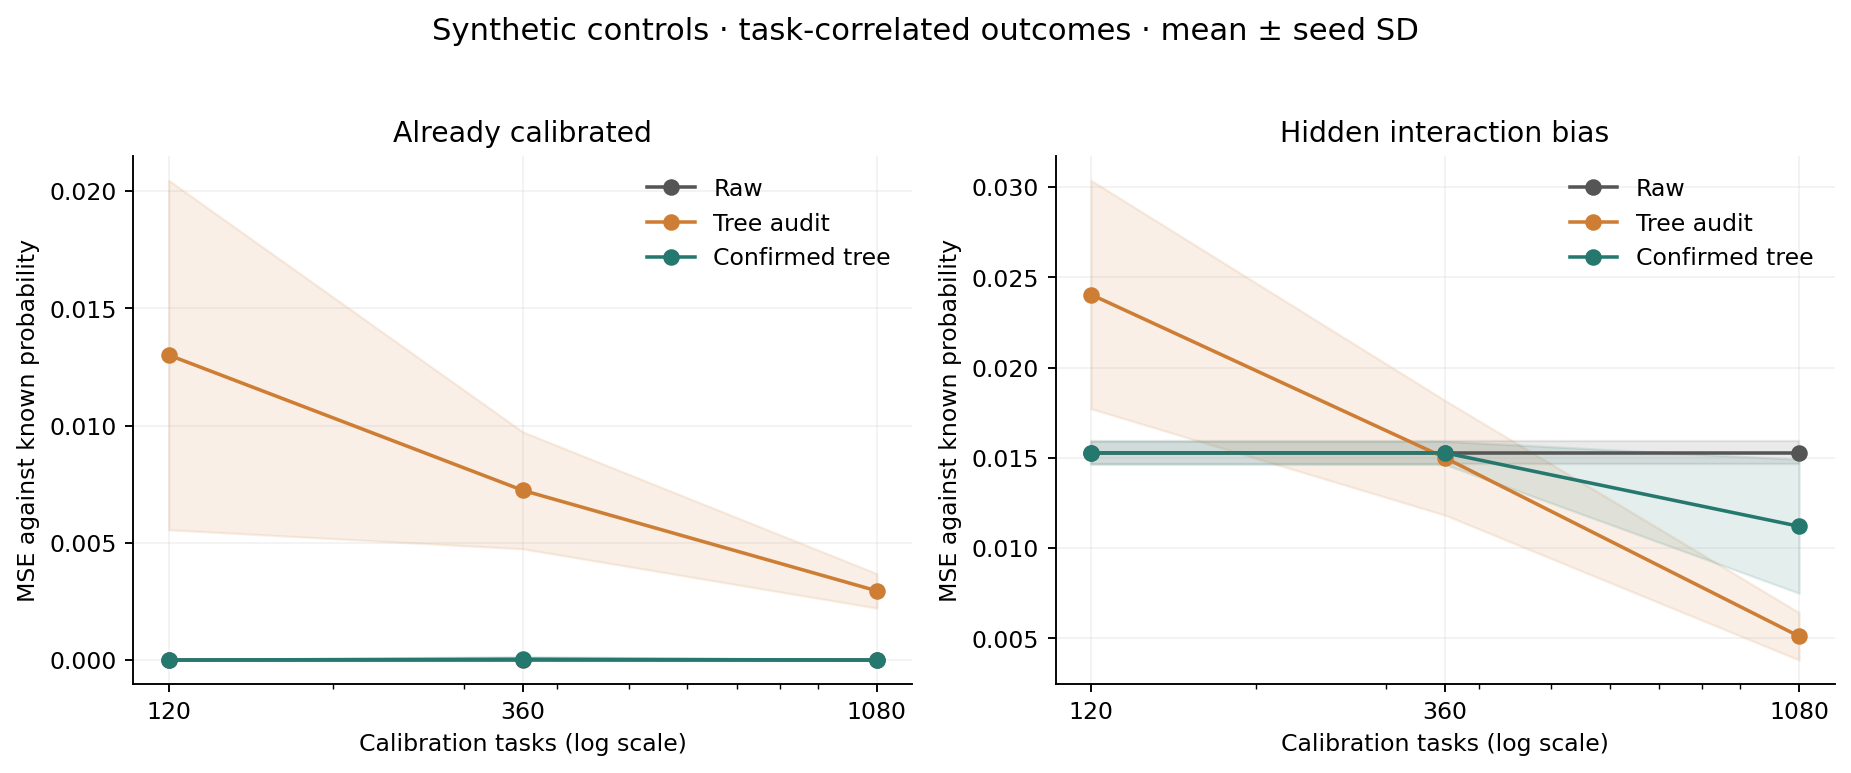

In [7]:
simulations = pd.read_csv(SIMULATIONS / "simulation_summary.csv")
display(simulations[["scenario", "calibration_tasks", "method", "known_probability_mse", "any_patch_rate", "seeds"]])
display(Image(filename=str(SIMULATIONS / "simulation_diagnostics.png")))


The reused-data auditor makes corrections in every calibrated-null run. At 120 calibration tasks those corrections add substantial known-probability error. Confirmation suppresses most false patches, but still makes one in ten null runs at size 360.

In the biased scenario with 1,080 calibration tasks, the unfiltered auditor removes more of the interaction error than the filter. The procedure therefore exhibits a resistance-to-noise versus power tradeoff, not universal superiority. Simulation shading is seed standard deviation; ten seeds do not establish an exact false-discovery rate.


## 6. Predict the value of escalation

A primary solution can be unlikely to pass even when its alternate is equally unlikely to pass. Routing therefore targets:

$$u(X)=E[y_{alternate}-y_{primary}\mid X].$$

A regularized regressor fits this signed difference using training tasks only. At inference it sees primary-answer features, not alternate outcomes. This is an observed paired-outcome prediction problem, not a causal treatment-effect estimate.

With primary/alternate costs of 1/4 and failure loss L, a cascade's objective is 1 + 4 P(escalate) + L P(final failure). The plug-in policy escalates when L times predicted benefit exceeds four. A direct alternate-only action is charged four, without a primary-generation stage.


## 7. Strong threshold controls and paired decision comparisons

Confidence policies choose validation cutoffs using both the original eleven-budget grid and an exact search over every score/tie boundary. The exact search uses cumulative observed paired benefits. The benefit model also has an exact validation-selected cutoff, so its comparison does not rely solely on a coarse confidence baseline.

Protocol v2 added this comparator after the first exploratory run. Both versions and the original grid results remain available. No test labels choose any policy threshold.


In [8]:
costs = pd.read_csv(RESULTS / "decision_costs.csv")
selected = costs[(costs["method"].isin(["logistic/platt", "histogram_boosting/platt", "benefit_model"])) &
                 costs["selector"].isin(["all_validation_boundaries", "predicted_benefit"])]
display(selected.groupby(["failure_loss", "method", "selector"])[["total_objective", "mean_compute", "success", "escalation"]].mean())
comparisons = pd.read_csv(RESULTS / "cost_comparisons.csv")
display(comparisons.query("method == 'benefit_model'")[["failure_loss", "selector", "objective_difference", "low", "high", "task_clusters"]])


total_objective  \
failure_loss method                   selector                                     
2            benefit_model            all_validation_boundaries         2.101801   
                                      predicted_benefit                 2.101801   
             histogram_boosting/platt all_validation_boundaries         2.101801   
             logistic/platt           all_validation_boundaries         2.101801   
5            benefit_model            all_validation_boundaries         3.748120   
                                      predicted_benefit                 3.739905   
             histogram_boosting/platt all_validation_boundaries         3.757725   
             logistic/platt           all_validation_boundaries         3.755513   
10           benefit_model            all_validation_boundaries         6.323791   
                                      predicted_benefit                 6.314123   
             histogram_boosting/platt all_validation_boundaries         6.513618   
             logistic/platt           all_validation_boundaries         6.510395   
20           benefit_model            all_validation_boundaries        11.473934   
                                      predicted_benefit                11.457757   
             histogram_boosting/platt all_validation_boundaries        11.801264   
             logistic/platt           all_validation_boundaries        11.823128   
50           benefit_model            all_validation_boundaries        26.221169   
                                      predicted_benefit                26.184013   
             histogram_boosting/platt all_validation_boundaries        26.079115   
             logistic/platt           all_validation_boundaries        26.139463   

                                                                 mean_compute  \
failure_loss method                   selector                                  
2            benefit_model            all_validation_boundaries      1.000000   
                                      predicted_benefit              1.000000   
             histogram_boosting/platt all_validation_boundaries      1.000000   
             logistic/platt           all_validation_boundaries      1.000000   
5            benefit_model            all_validation_boundaries      1.150016   
                                      predicted_benefit              1.102622   
             histogram_boosting/platt all_validation_boundaries      1.004171   
             logistic/platt           all_validation_boundaries      1.001011   
10           benefit_model            all_validation_boundaries      1.186667   
                                      predicted_benefit              1.192480   
             histogram_boosting/platt all_validation_boundaries      1.011880   
             logistic/platt           all_validation_boundaries      1.002022   
20           benefit_model            all_validation_boundaries      1.449289   
                                      predicted_benefit              1.580979   
             histogram_boosting/platt all_validation_boundaries      2.124803   
             logistic/platt           all_validation_boundaries      2.008910   
50           benefit_model            all_validation_boundaries      2.406003   
                                      predicted_benefit              2.495229   
             histogram_boosting/platt all_validation_boundaries      2.624139   
             logistic/platt           all_validation_boundaries      2.638673   

                                                                 success  \
failure_loss method                   selector                             
2            benefit_model            all_validation_boundaries 0.449100   
                                      predicted_benefit         0.449100   
             histogram_boosting/platt all_validation_boundaries 0.449100   
             logistic/platt           all_validation_

,failure_loss,selector,objective_difference,low,high,task_clusters
1,2,all_validation_boundaries,0.000000,0.000000,0.000000,1055
2,2,predicted_benefit,0.000000,0.000000,0.000000,1055
25,5,all_validation_boundaries,-0.007393,-0.023476,0.010115,1055
26,5,predicted_benefit,-0.015608,-0.025155,-0.005555,1055
49,10,all_validation_boundaries,-0.186603,-0.252893,-0.130675,1055
50,10,predicted_benefit,-0.196272,-0.267930,-0.137564,1055
73,20,all_validation_boundaries,-0.349194,-0.453400,-0.239112,1055
74,20,predicted_benefit,-0.365371,-0.474439,-0.257675,1055
97,50,all_validation_boundaries,0.081706,-0.208242,0.412987,1055
98,50,predicted_benefit,0.044550,-0.230788,0.344316,1055


Under the stipulated loss 20 scenario, the plug-in benefit model reduces the mean objective relative to exact-threshold logistic/Platt. At loss 50, its mean difference reverses sign and the descriptive interval spans zero. This is scenario-dependent decision value, not measured compute savings.

The task-cost archive retains every task's mean objective for each repeat, policy and loss scenario. The same overlapping-fit limitations apply to the cost intervals. Confidence-estimation overhead, actual model prices and production latency are not measured.


## 8. Transfer under changed feature mixtures

Training-task medians of task-average AST depth and prompt length define high/low task groups. The analysis retrospectively changes their share in the held-out mixture, preserving recorded outcomes and reporting effective task counts.

This is a covariate-mixture stress test. It neither creates new outcomes nor models a change in the conditional relationship between features and correctness. It is not a temporal transfer or fresh-benchmark evaluation.


mean        min
feature          target_high_fraction                      
ast_depth        0.000000             107.733333  98.000000
                 0.250000             171.394448 158.909417
                 0.500000             210.135861 208.037915
                 0.750000             165.704870 152.020779
                 1.000000             103.266667  93.000000
log_prompt_chars 0.000000             105.800000  93.000000
                 0.250000             168.984556 152.020779
                 0.500000             210.315324 208.037915
                 0.750000             168.218877 154.802458
                 1.000000             105.200000  95.000000

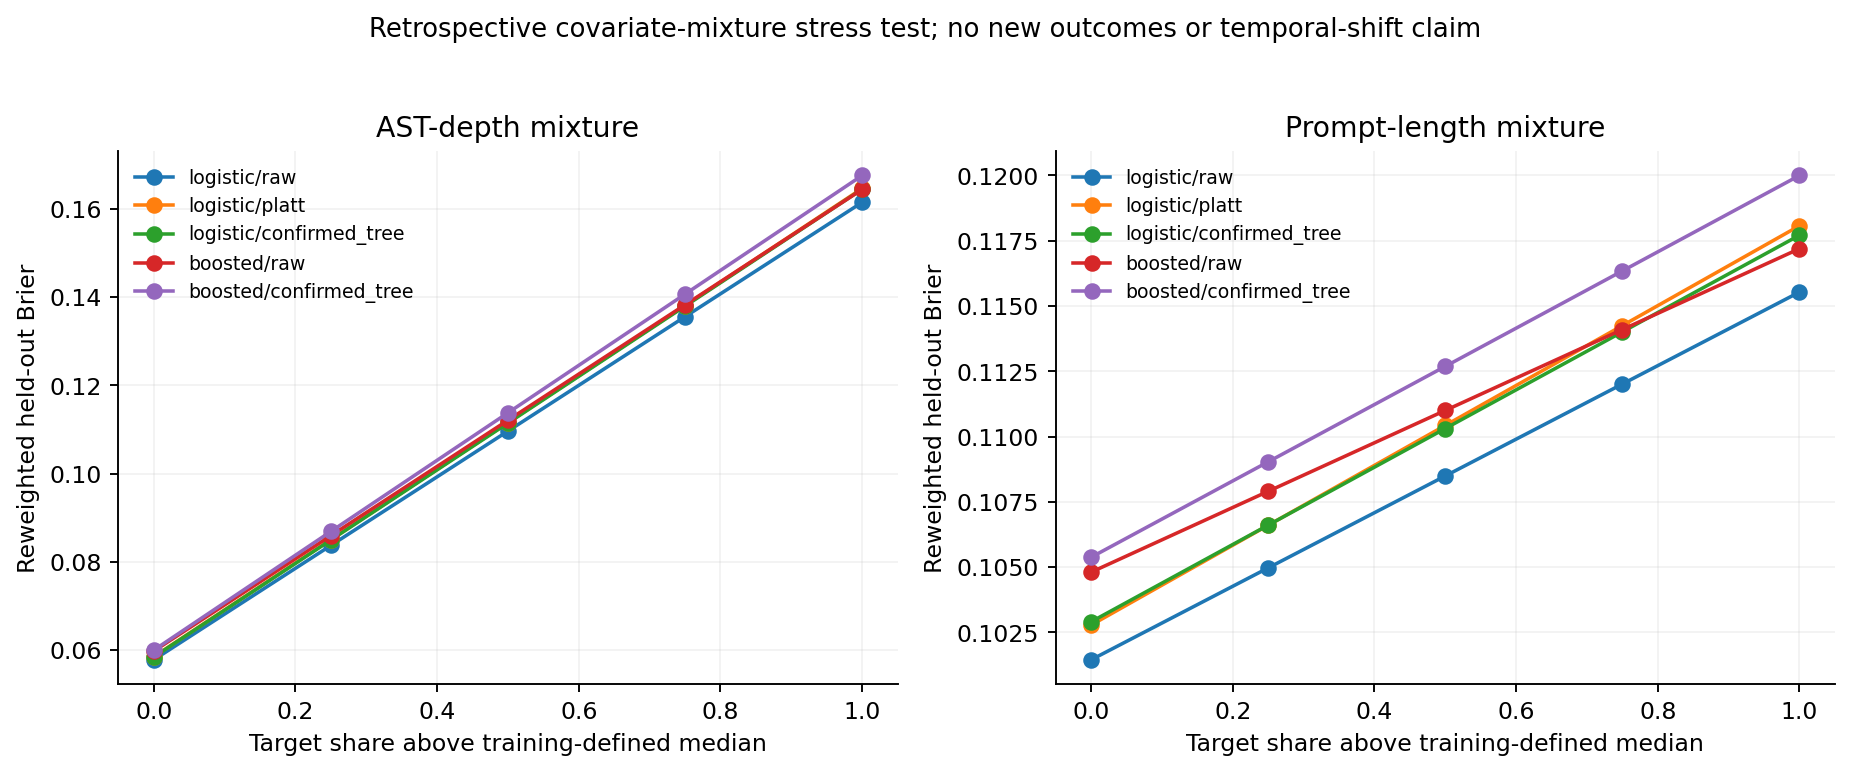

In [9]:
shift = pd.read_csv(RESULTS / "mixture_shift.csv")
display(shift.groupby(["feature", "target_high_fraction"])["effective_tasks"].agg(["mean", "min"]))
display(Image(filename=str(RESULTS / "mixture_diagnostics.png")))


## 9. What the investigation supports

The outcomes support a more specific research account than 'calibration makes confidence better':

- A flexible residual auditor can fit selected noise; the known-probability null makes the distortion observable.
- Fresh confirmation suppresses many patches but needs enough independent tasks to detect real structure.
- More flexible base prediction and post-processing do not automatically improve this dataset's probabilities.
- Estimating which action helps can change decisions even when score calibration adds little.
- Data dependence, validation choices, policy costs and distribution assumptions change the interpretation.

This is a fixed set of candidate configurations, with different capacities and estimation procedures. It does not isolate one causal component or establish an optimally tuned winner. All benchmark results reuse an inspected sample of 1,055 task clusters. New confirmatory performance claims would require new evaluation data.


## Reproduction and source records

```bash
python -m research.advanced --output work/new-advanced
python -m research.simulations --output work/new-simulations
python -m research.advanced_figures --results work/new-advanced --simulations work/new-simulations
python -m unittest discover -s research -t . -v
```

Fresh output paths are required. Smoke runs are marked incomplete and are rejected by this full-study notebook. Original reference notebooks and results remain unchanged. See [ADVANCED_METHODS.md](ADVANCED_METHODS.md) for exact settings, role assignments, assumptions and related work.

Foundations: [multicalibration](https://proceedings.mlr.press/v80/hebert-johnson18a.html), [MCBoost](https://joss.theoj.org/papers/10.21105/joss.03453), [confidence scoring for LLMs](https://proceedings.mlr.press/v235/detommaso24a.html). This is a separately dated public-data implementation and evaluation, not evidence of an earlier private Cursor deployment or an invented calibration theorem.
